# Unit 4: Memvalidasi Data
**Kode unit:** J.62DMI00.006.1 · SKKNI No. 299 Tahun 2020 · Proyek: *Prediksi Arah Harian IHSG*

**Tujuan unit ini:** memeriksa kualitas data sebelum dipakai.

In [1]:
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 110

In [2]:
df = pd.read_csv('../data/raw/market_data.csv', parse_dates=['Date'])

## Cek 1 — Apakah ada data kosong?

In [3]:
kosong = df.isnull().sum()
print(kosong)
df[df.isnull().any(axis=1)]

Date       0
OIL        1
GOLD       1
USDIDR     0
SP500      1
IHSG       1
VIX        1
CPI        0
BI_rate    0
US_rate    0
dtype: int64


,Date,OIL,GOLD,USDIDR,SP500,IHSG,VIX,CPI,BI_rate,US_rate
0,2010-01-01,NaN,NaN,9385.599609,NaN,NaN,NaN,5.134206,6.5,0.11


## Cek 2 — Apakah ada tanggal ganda?

In [4]:
print('Jumlah tanggal ganda:', df['Date'].duplicated().sum())

Jumlah tanggal ganda: 0


## Cek 3 — Apakah ada nilai yang tidak masuk akal (harga ≤ 0)?

In [5]:
for k in ['IHSG', 'SP500', 'OIL', 'GOLD', 'USDIDR', 'VIX']:
    salah = df[df[k] <= 0]
    if len(salah) > 0:
        print(k, '→', salah[['Date', k]].to_string(index=False))

OIL →       Date        OIL
2020-04-20 -37.630001


Harga minyak **−37,63 USD** pada 20 April 2020 memang pernah terjadi (kontrak minyak AS saat itu), tetapi nilai
negatif membuat perhitungan persentase perubahan menjadi kacau. Nilai ini akan diperbaiki di Unit 6.

## Cek 4 — Apakah ada kurs USD/IDR yang janggal?
Sebuah nilai dianggap janggal bila berbeda **lebih dari 4%** dari nilai tengah (median) 21 hari di sekitarnya.
Rupiah tidak pernah melonjak 4% lalu kembali normal keesokan harinya.

Jumlah kurs janggal: 15
      Date       USDIDR
2010-11-01   888.109985
2012-02-07   892.000000
2013-07-22  9612.450195
2013-10-14 10787.000000
2013-10-21 10758.000000
2013-10-28  9612.450195
2013-11-11  9612.450195
2013-11-18  9612.450195
2013-11-25  9612.450195
2013-11-29  9612.450195
2013-12-02  9612.450195
2013-12-03  9612.450195
2013-12-06  9612.450195
2013-12-09  9610.000000
2024-12-26 15069.400391


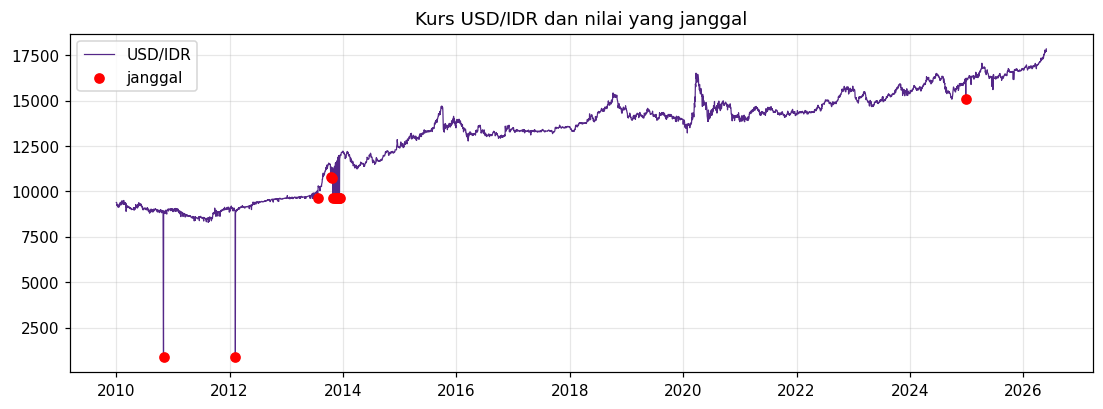

In [6]:
median21 = df['USDIDR'].rolling(21, center=True, min_periods=5).median()
janggal = (df['USDIDR'] / median21 - 1).abs() > 0.04
print('Jumlah kurs janggal:', janggal.sum())
print(df.loc[janggal, ['Date', 'USDIDR']].to_string(index=False))

plt.figure(figsize=(12, 4))
plt.plot(df['Date'], df['USDIDR'], linewidth=0.8, color='#542788', label='USD/IDR')
plt.scatter(df.loc[janggal, 'Date'], df.loc[janggal, 'USDIDR'], color='red', zorder=3, label='janggal')
plt.title('Kurs USD/IDR dan nilai yang janggal')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig('../figures/04_kurs_janggal.png', dpi=150, bbox_inches='tight')
plt.show()

## Cek 5 — Apakah semua baris adalah hari bursa BEI?
Pada hari libur BEI (misalnya Lebaran), nilai IHSG hanya **disalin** dari hari sebelumnya sehingga terlihat tidak berubah.

In [7]:
libur = df['IHSG'].diff() == 0
print('Jumlah hari IHSG tidak berubah (libur BEI):', libur.sum())
print('Contoh Lebaran 2010:', df.loc[libur & (df['Date'].dt.year == 2010) & (df['Date'].dt.month == 9), 'Date'].dt.date.tolist())

Jumlah hari IHSG tidak berubah (libur BEI): 300
Contoh Lebaran 2010: [datetime.date(2010, 9, 8), datetime.date(2010, 9, 9), datetime.date(2010, 9, 10), datetime.date(2010, 9, 13), datetime.date(2010, 9, 14)]


## Cek 6 — Seberapa sering variabel makro berubah?

In [8]:
for k in ['CPI', 'BI_rate', 'US_rate']:
    print(f'{k:8s}: {df[k].nunique():3d} nilai berbeda selama 16 tahun')

CPI     :  17 nilai berbeda selama 16 tahun
BI_rate :  18 nilai berbeda selama 16 tahun
US_rate :  81 nilai berbeda selama 16 tahun


`CPI` hanya berubah sekali setahun dan sudah tercantum sejak 1 Januari, padahal angka inflasi setahun baru diketahui
di akhir tahun. Suku bunga juga jarang berubah. Ketiganya kurang berguna untuk menebak arah harian.

## Ringkasan hasil validasi

| No | Masalah | Jumlah | Tindakan (Unit 5–6) |
|---|---|---|---|
| 1 | Baris kosong (1 Jan 2010, libur Tahun Baru) | 1 baris | Dihapus |
| 2 | Tanggal ganda | 0 | – |
| 3 | Harga minyak negatif | 1 nilai | Diganti nilai hari sebelumnya |
| 4 | Kurs USD/IDR janggal | 15 nilai | Diganti nilai hari sebelumnya |
| 5 | Hari libur BEI (IHSG disalin) | 300 baris | Dihapus |
| 6 | CPI, BI_rate, US_rate jarang berubah | 3 kolom | Tidak dipakai |

**Kesimpulan:** data layak dipakai setelah diperbaiki.